<h1>Train — ConvNeXt-Tiny</h1>

Trains and evaluates ConvNeXt-Tiny using the tuned hyperparameters from `ARCH_HYPERPARAMS["convnext_tiny"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: off
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']
Train: 1348 | Val: 323 | Test: 856


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["convnext_tiny"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ConvNeXt-Tiny: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders — its own (capped) batch size, and
# (for InceptionNet v3) its own image size.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ConvNeXt-Tiny: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 32)


## Define the model

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with ConvNeXt-Tiny)
# ---------------------------------------------------------
model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)

model.avgpool = nn.AdaptiveMaxPool2d(1)

in_f = model.classifier[2].in_features
model.classifier[2] = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
# criterion = FocalLoss(weight=class_weights_arch, gamma=2.0)  # parked for later -- see todo.txt

optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)

scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ConvNeXt-Tiny] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[ConvNeXt-Tiny] Epoch   1/100 | LR: 9.93e-05 | train loss 0.8667 acc 0.639 | val loss 0.7529 acc 0.663 *


[ConvNeXt-Tiny] Epoch   2/100 | LR: 9.93e-05 | train loss 0.3999 acc 0.803 | val loss 0.5105 acc 0.805 *


[ConvNeXt-Tiny] Epoch   3/100 | LR: 9.93e-05 | train loss 0.2351 acc 0.900 | val loss 0.5217 acc 0.820


[ConvNeXt-Tiny] Epoch   4/100 | LR: 9.93e-05 | train loss 0.1440 acc 0.923 | val loss 0.4634 acc 0.824 *


...

[ConvNeXt-Tiny] Epoch  10/100 | LR: 9.93e-05 | train loss 0.0226 acc 0.990 | val loss 0.6016 acc 0.861


[ConvNeXt-Tiny] Epoch  11/100 | LR: 9.93e-05 | train loss 0.0373 acc 0.989 | val loss 0.6181 acc 0.833


[ConvNeXt-Tiny] Epoch  12/100 | LR: 9.93e-05 | train loss 0.0765 acc 0.971 | val loss 0.6470 acc 0.814


[ConvNeXt-Tiny] Epoch  13/100 | LR: 9.93e-05 | train loss 0.1067 acc 0.961 | val loss 0.5531 acc 0.842


[ConvNeXt-Tiny] Epoch  14/100 | LR: 9.93e-05 | train loss 0.0157 acc 0.993 | val loss 0.6653 acc 0.854

[ConvNeXt-Tiny] No val loss improvement for 10 epochs — stopping early at epoch 14.

[ConvNeXt-Tiny] Restored best checkpoint (val loss = 0.4634)


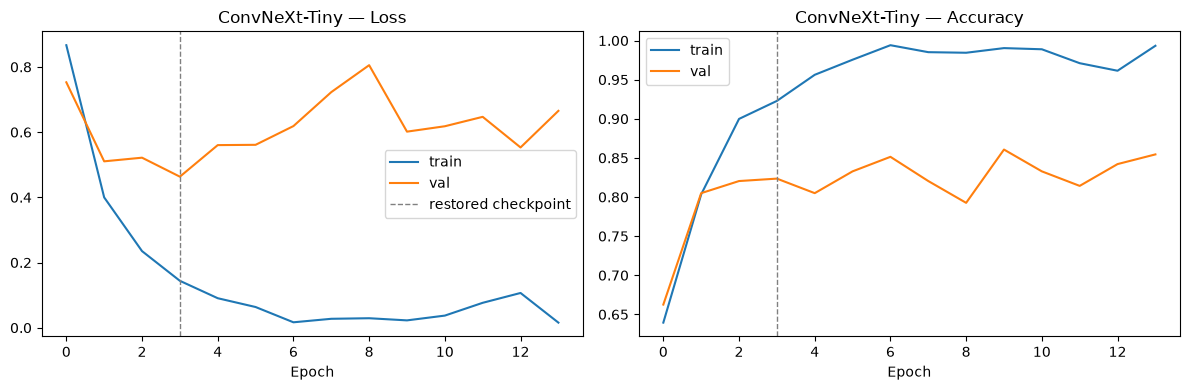

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ConvNeXt-Tiny", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ConvNeXt-Tiny")

## Evaluate on the test set

[ConvNeXt-Tiny] Test accuracy: 0.798


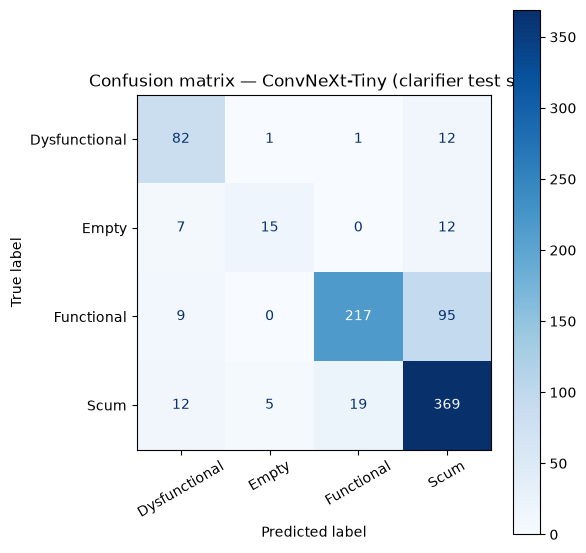

               precision    recall  f1-score   support

Dysfunctional      0.745     0.854     0.796        96
        Empty      0.714     0.441     0.545        34
   Functional      0.916     0.676     0.778       321
         Scum      0.756     0.911     0.826       405

     accuracy                          0.798       856
    macro avg      0.783     0.721     0.736       856
 weighted avg      0.813     0.798     0.794       856



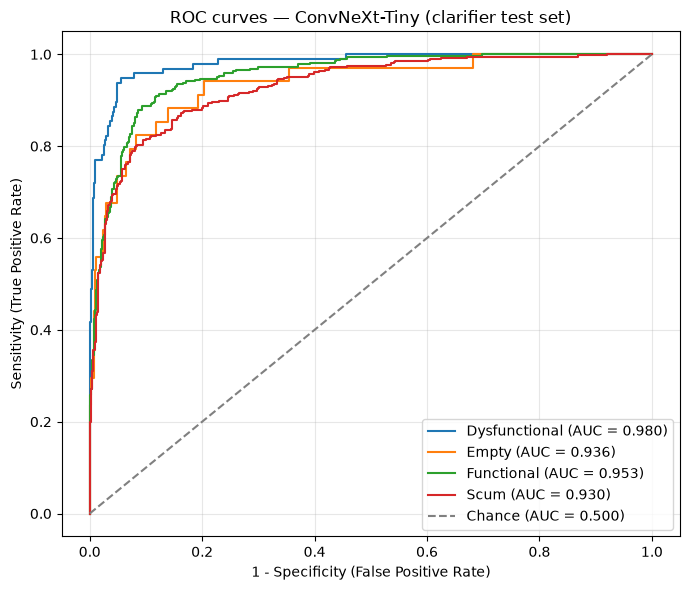

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.980
  Empty          : 0.936
  Functional     : 0.953
  Scum           : 0.930

Mean AUC (over 4/4 classes with test examples): 0.950


(np.float64(0.7978971962616822),
 {'Dysfunctional': 0.9800712719298247,
  'Empty': 0.9355946758265351,
  'Functional': 0.9534282470084724,
  'Scum': 0.9295940434151816})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ConvNeXt-Tiny", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

In [6]:
save_result("ConvNeXt-Tiny", "convnext_tiny")

Saved results to ../results/clarifier_noaug/results_clarifier_convnext_tiny_chronological.pkl
Saved model weights to ../models/pad/clarifier_convnext_tiny_cnn.pt
